# Credit Card Transactions Fraud Detection · 03 Feature Engineering

# Aim, Objective, and Motivation
- **Aim:** <u>turn</u> the EDA findings into model-ready features **without leaking the future**.
- **Objective:** build transaction-level and per-card history features, verify they are causal,
  and save time-based train / valid / test sets.
- **Motivation:** the biggest flaw of my first version was leakage — features computed over the whole two years
  and a random split. Here every feature uses only information available *at the moment of the transaction*.

# Outlines
1. What is data leakage?
2. Load full timeline
3. Transaction-level features
4. Card history features
5. Leakage check (brute force)
6. Time-based split
7. Feature overview on the training set
8. Save datasets
9. Summary

<!-- objective -->
## Objective

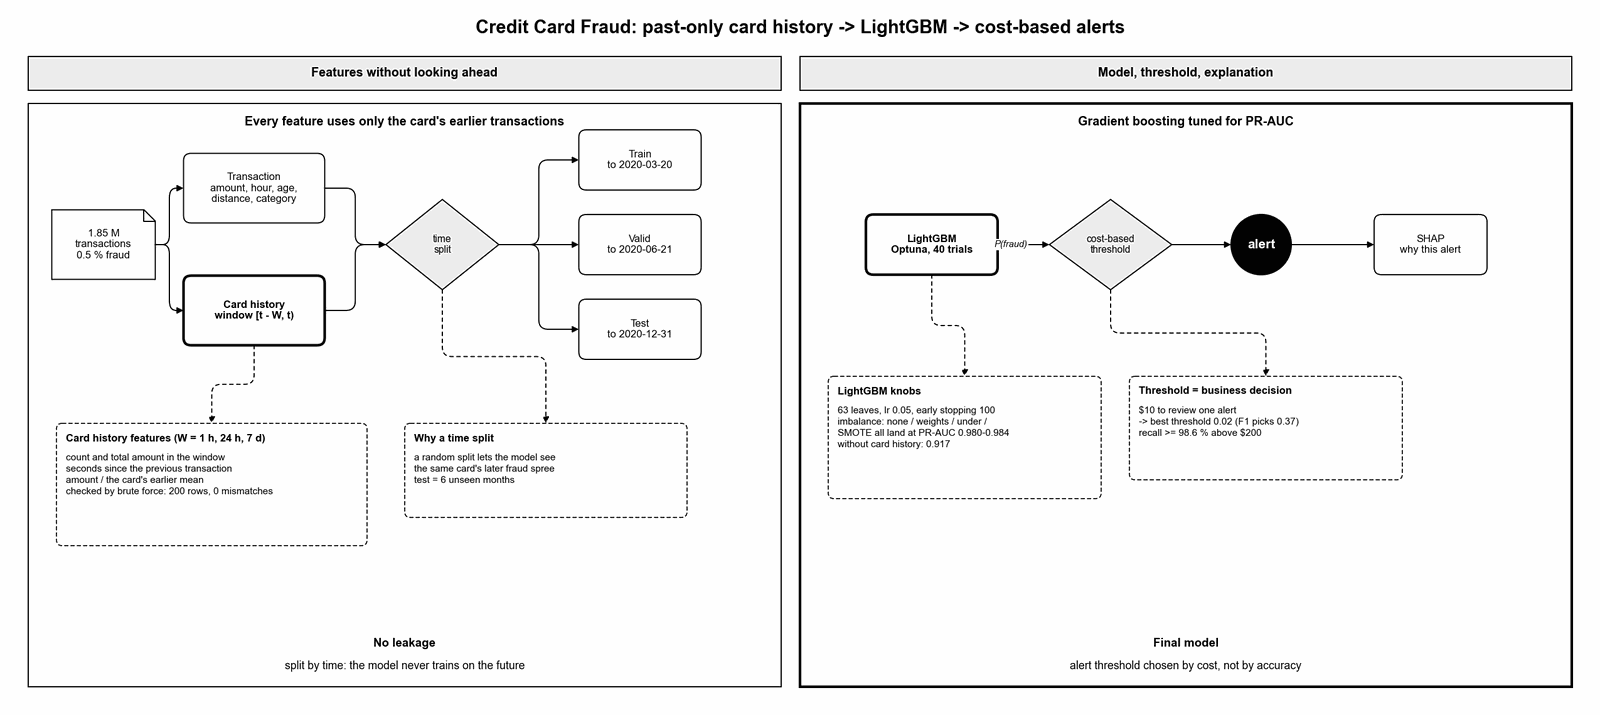

- **Problem** → about 1 in 200 card payments is fraud, and a fraud team can only review so many alerts a day
- **Why this repo** → rank every payment by fraud risk using only what the bank knew *at that moment*, then pick the alert threshold from the cost of a review, not from accuracy
- **Real-world use** → an alert queue: the riskiest payments go to an analyst (or trigger an SMS check) first; the threshold slider trades missed fraud against analyst workload

In [1]:
# ---------------------------------------------------------------- Imports
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import COLORS, LABELS, TARGET, VALID_START
from src.data import load_all, save_processed
from src.features import (add_transaction_features, add_card_history_features,
                          NUMERIC_FEATURES, CATEGORICAL_FEATURES, FEATURES)
from src.plotting import set_style, savefig

# ---------------------------------------------------------------- Global constants
WINDOWS = ("1h", "24h", "7d")             # look-back windows for card history
N_CHECK_ROWS = 200                        # rows verified by brute force in the leakage check
CHECK_SEED = 7
KEEP_COLS = ["trans_id", "trans_time", "card_id", "amount", TARGET] + [f for f in FEATURES if f != "amount"]
SPLIT_COLORS = {"train": "#4b5563", "valid": "#9ca3af", "test": COLORS[1]}

set_style()

# [1/9] What is data leakage?
> **Definition:** information used to train or evaluate the model that would **not be available at prediction time**.
> Leakage makes offline scores look great and the model fail in production.

Two leaks in my first version, and the fix used here:

| Leak | Example | Fix |
|---|---|---|
| **Future information in features** | `transaction_count` per card counted over all 2 years — a January transaction "knew" about December | only look **backwards**: window $[t - W,\ t)$ |
| **Random split on time-ordered data** | train and test shuffled together → the model trains on the days around each test transaction | **time-based split**: train < valid < test |

A feature $x_i$ for transaction $i$ at time $t_i$ on card $c$ is **causal** if it depends only on
$\{\text{transaction } j : c_j = c,\ t_j < t_i\}$ plus transaction $i$'s own fields (amount, time, category …) — never on the label.

# [2/9] Load full timeline
> **Objective:** <u>stack</u> train and test into one timeline sorted by time.
>
> **Question:** isn't combining train and test itself a leak? **No** — a card's history at the start of the test period
> legitimately includes its earlier (train-period) transactions; a real system would know them too. Labels are never used
> to build features, and the split happens afterwards by time.

In [2]:
raw = load_all()

In [3]:
print(f"{len(raw):,} transactions from {raw.trans_time.min()} to {raw.trans_time.max()}")
raw.groupby("source")[TARGET].agg(["size", "mean"])

1,852,394 transactions from 2019-01-01 00:00:18 to 2020-12-31 23:59:34


,size,mean
source,,
test,555719,0.003860
train,1296675,0.005789


# [3/9] Transaction-level features
> **Objective:** <u>derive</u> features from the transaction's own fields (no history needed).

| Feature | Formula / rule | Why (EDA) |
|---|---|---|
| `hour`, `day_of_week` | from `trans_time` | fraud peaks at night |
| `is_night` | $1$ if hour $\in \{22, 23, 0, 1, 2, 3\}$ | 15–30× higher fraud rate |
| `age` | $\frac{t - \text{dob}}{365.25}$ in years **at transaction time** (old version used *today*) | older holders slightly more at risk |
| `log_amount` | $\ln(1 + \text{amount})$ | amount is heavily right-skewed |
| `log_city_pop` | $\ln(1 + \text{city\_pop})$ | skewed |
| `distance_km` | haversine(holder, merchant) | test whether distance matters |
| `is_male` | $1$ if gender = M | binary encoding |

In [4]:
tx = add_transaction_features(raw)
new_tx_cols = ["hour", "day_of_week", "is_night", "age", "log_amount", "log_city_pop", "distance_km", "is_male"]

In [5]:
tx[new_tx_cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
hour,1852394.0,12.81,6.82,0.00,7.00,14.00,19.00,23.00
day_of_week,1852394.0,2.97,2.20,0.00,1.00,3.00,5.00,6.00
is_night,1852394.0,0.23,0.42,0.00,0.00,0.00,0.00,1.00
age,1852394.0,46.26,17.41,13.92,32.89,44.24,57.31,96.17
log_amount,1852394.0,3.53,1.29,0.69,2.36,3.88,4.43,10.27
log_city_pop,1852394.0,8.36,2.45,3.18,6.61,7.80,9.92,14.88
distance_km,1852394.0,76.11,29.12,0.02,55.32,78.22,98.51,152.12
is_male,1852394.0,0.45,0.50,0.00,0.00,0.00,1.00,1.00


# [4/9] Card history features
> **Objective:** <u>capture</u> the fraud **burst** pattern: many, large, fast transactions on one card.
>
> **Formulas** for transaction $i$ on card $c$ at time $t_i$ and window $W$:
> - $\text{card\_txn\_count}_W(i) = \#\{j : c_j = c,\ t_i - W \le t_j < t_i\}$
> - $\text{card\_amount\_sum}_W(i) = \sum_{j:\ c_j = c,\ t_i - W \le t_j < t_i} \text{amount}_j$
> - $\text{secs\_since\_prev\_txn}(i) = t_i - t_{\text{prev}(i)}$
> - $\text{amount\_vs\_card\_mean}(i) = \dfrac{\text{amount}_i}{\text{mean}\{\text{amount}_j : c_j = c,\ t_j < t_i\}}$
> - $\text{card\_txn\_index}(i)$ = number of earlier transactions on the card
>
> The window is **left-closed** $[t_i - W,\ t_i)$: the current transaction is excluded (pandas `rolling(W, closed="left")`).

In [6]:
feat = add_card_history_features(tx, windows=WINDOWS)
history_cols = [c for c in feat.columns if c.startswith("card_") and c != "card_id"] + \
               ["secs_since_prev_txn", "amount_vs_card_mean"]

In [7]:
feat[history_cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
card_txn_index,1852394.0,1298.90,969.45,0.0,509.00,1109.00,1917.00,4391.00
card_txn_count_1h,1852394.0,0.20,0.48,0.0,0.00,0.00,0.00,8.00
card_amount_sum_1h,1852394.0,15.01,95.90,0.0,0.00,0.00,0.00,27390.12
card_txn_count_24h,1852394.0,4.11,3.26,0.0,2.00,3.00,6.00,35.00
card_amount_sum_24h,1852394.0,289.43,430.52,0.0,72.26,183.52,364.24,29773.37
card_txn_count_7d,1852394.0,26.49,14.78,0.0,16.00,24.00,34.00,109.00
card_amount_sum_7d,1852394.0,1844.34,1446.48,0.0,901.04,1493.04,2378.67,31809.15
secs_since_prev_txn,1851395.0,30939.48,45328.99,0.0,5698.00,15695.00,38135.00,1341471.00
amount_vs_card_mean,1851395.0,1.01,2.59,0.0,0.16,0.67,1.20,676.39


**Note:** `secs_since_prev_txn` and `amount_vs_card_mean` are missing (NaN) only for each card's very first transaction
(999 rows) — there is no history yet. Tree models handle NaN natively; for linear models we impute in notebook 04.

In [8]:
feat[history_cols].isna().sum().loc[lambda s: s > 0]

secs_since_prev_txn    999
amount_vs_card_mean    999
dtype: int64

# [5/9] Leakage check (brute force)
> **Question:** do the vectorised rolling features really use only the past?
>
> **Method:** for random transactions, recompute every history feature with a slow, obviously-correct loop over that card's
> earlier transactions and compare with the fast version.

In [9]:
rng = np.random.default_rng(CHECK_SEED)
sample_idx = rng.choice(len(feat), N_CHECK_ROWS, replace=False)
by_card = {c: g.sort_values("trans_time") for c, g in feat[feat.card_id.isin(feat.card_id.iloc[sample_idx])]
           .groupby("card_id", observed=True)}

mismatches = []
for i in sample_idx:
    row = feat.iloc[i]
    hist = by_card[row.card_id]
    past = hist[hist.trans_time < row.trans_time]
    expected = {"card_txn_index": len(past)}
    for w in WINDOWS:
        in_w = past[past.trans_time >= row.trans_time - pd.Timedelta(w)]
        expected[f"card_txn_count_{w}"] = len(in_w)
        expected[f"card_amount_sum_{w}"] = in_w.amount.sum()
    if len(past):
        expected["amount_vs_card_mean"] = row.amount / past.amount.mean()
    for k, v in expected.items():
        if not np.isclose(row[k], v, rtol=1e-4, atol=1e-2):
            mismatches.append((i, k, row[k], v))

In [10]:
print(f"checked {N_CHECK_ROWS} random transactions x {len(expected)} features -> {len(mismatches)} mismatches")
mismatches[:5]

checked 200 random transactions x 8 features -> 0 mismatches


[]

**Answer:** 0 mismatches → the fast features match the brute-force "past only" definition: **no future leakage**.

# [6/9] Time-based split
> **Objective:** <u>split</u> by time, as the model would be used in reality.

| Set | Period | Used for |
|---|---|---|
| **train** | 2019-01-01 → 2020-03-20 | fitting models |
| **valid** | 2020-03-21 → 2020-06-21 (end of `fraudTrain`) | model selection, tuning, threshold |
| **test** | 2020-06-21 → 2020-12-31 (`fraudTest`) | **one** final, unbiased evaluation |

In [11]:
feat["split"] = np.where(feat.source == "test", "test",
                         np.where(feat.trans_time < pd.Timestamp(VALID_START), "train", "valid"))
split_summary = feat.groupby("split").agg(start=("trans_time", "min"), end=("trans_time", "max"),
                                          rows=(TARGET, "size"), frauds=(TARGET, "sum"), fraud_rate=(TARGET, "mean"))
split_summary = split_summary.loc[["train", "valid", "test"]]

weekly = feat.set_index("trans_time").groupby([pd.Grouper(freq="W"), "split"])[TARGET].size().unstack()
fig, ax = plt.subplots(figsize=(14, 3.8))
for s, c in SPLIT_COLORS.items():
    ax.fill_between(weekly.index, weekly[s].fillna(0), step="mid", color=c, alpha=0.8, label=s)
ax.set(title="Time-based split (transactions per week)", ylabel="transactions")
ax.legend(loc="upper left")
savefig(fig, "03_time_split")
plt.close(fig)

In [12]:
split_summary.assign(fraud_rate=lambda d: (d.fraud_rate * 100).round(3).astype(str) + " %")

,start,end,rows,frauds,fraud_rate
split,,,,,
train,2019-01-01 00:00:18,2020-03-20 23:58:44,1070966,6250,0.584 %
valid,2020-03-21 00:00:20,2020-06-21 12:13:37,225709,1256,0.556 %
test,2020-06-21 12:14:25,2020-12-31 23:59:34,555719,2145,0.386 %


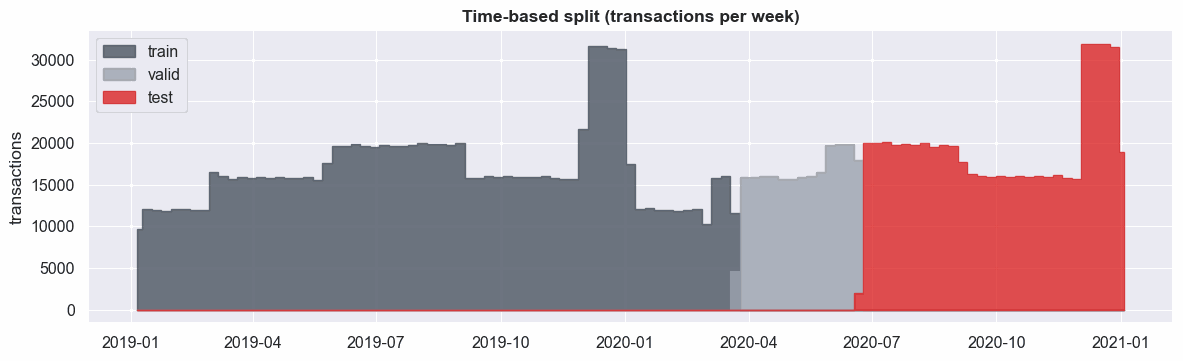

In [13]:
fig

# [7/9] Feature overview on the training set
> **Objective:** <u>confirm</u> the final features separate the classes (training rows only).
>
> **Formula (standardised mean difference):** $\text{SMD} = \dfrac{\bar{x}_{fraud} - \bar{x}_{legit}}{\sqrt{(s^2_{fraud} + s^2_{legit})/2}}$
> — |SMD| > 0.2 small, > 0.5 medium, > 0.8 large.

In [14]:
tr = feat[feat.split == "train"]
f1, f0 = tr[tr[TARGET] == 1], tr[tr[TARGET] == 0]
overview = pd.DataFrame({
    "legit_mean": f0[NUMERIC_FEATURES].mean(),
    "fraud_mean": f1[NUMERIC_FEATURES].mean(),
    "smd": (f1[NUMERIC_FEATURES].mean() - f0[NUMERIC_FEATURES].mean())
           / np.sqrt((f1[NUMERIC_FEATURES].var() + f0[NUMERIC_FEATURES].var()) / 2),
}).sort_values("smd", key=abs, ascending=False)

fig, ax = plt.subplots(figsize=(10, 6))
s = overview["smd"].sort_values()
ax.barh(s.index, s.values, color=[COLORS[1] if v > 0 else COLORS[0] for v in s.values])
ax.axvline(0, c="black", lw=0.8)
ax.set(title="Standardised mean difference (fraud vs legit, train)", xlabel="SMD")
savefig(fig, "03_feature_smd")
plt.close(fig)

In [15]:
overview.round(3)

,legit_mean,fraud_mean,smd
is_night,0.231,0.846,1.567
amount,67.625,530.634,1.559
card_amount_sum_24h,268.268,1936.158,1.499
log_amount,3.521,5.563,1.398
amount_vs_card_mean,0.990,6.928,1.132
card_amount_sum_7d,1761.114,3357.271,0.884
card_amount_sum_1h,12.366,415.831,0.796
card_txn_count_1h,0.189,0.679,0.656
card_txn_count_7d,25.358,18.558,-0.529
card_txn_index,752.186,509.071,-0.454


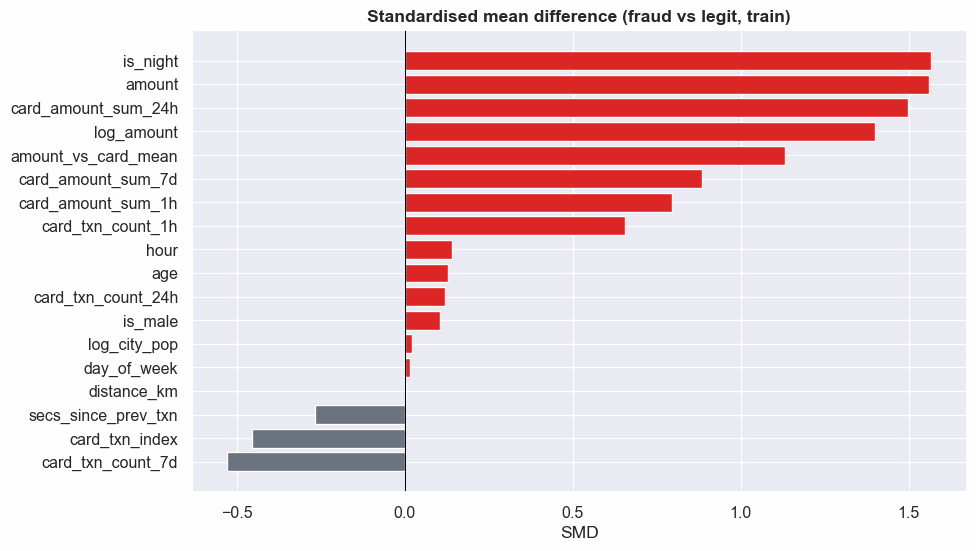

In [16]:
fig

**Answer:** `amount` / `log_amount`, `is_night`, `card_amount_sum_24h` and `amount_vs_card_mean` separate the classes
most strongly, consistent with the EDA tests. `distance_km` and `log_city_pop` are ≈ 0 as expected.

# [8/9] Save datasets
> **Objective:** <u>store</u> each split as Parquet (keeps dtypes, ~10× smaller than CSV) in `data/processed/` (git-ignored).
> Identifiers (`trans_id`, `card_id`, `trans_time`) are kept for analysis only — they are **not** model inputs.

In [17]:
sizes = {}
for s in ["train", "valid", "test"]:
    part = feat.loc[feat.split == s, KEEP_COLS].reset_index(drop=True)
    save_processed(part, s)
    sizes[s] = part.shape

In [18]:
print("model features:", len(FEATURES), "->", FEATURES)
sizes

model features: 19 -> ['amount', 'log_amount', 'hour', 'day_of_week', 'is_night', 'age', 'is_male', 'log_city_pop', 'distance_km', 'secs_since_prev_txn', 'card_txn_index', 'amount_vs_card_mean', 'card_txn_count_1h', 'card_amount_sum_1h', 'card_txn_count_24h', 'card_amount_sum_24h', 'card_txn_count_7d', 'card_amount_sum_7d', 'category']


{'train': (1070966, 23), 'valid': (225709, 23), 'test': (555719, 23)}

# [9/9] Summary
- **18 numeric + 1 categorical** features: transaction-level (time, age, amount, distance) and card history
  (gap since previous transaction, rolling 1h / 24h / 7d counts and spend, amount vs usual).
- Every history feature is **causal** — verified by brute force on random transactions.
- **Time-based split:** train (Jan 2019 – Mar 2020), valid (Mar – Jun 2020), test (Jun – Dec 2020).
- Dropped on purpose: identifiers, names, street, `merchant`, `job`, `state`, `city`, `zip`, `unix_time`.